In [ ]:
import numpy as np

# Modul sis (ako nije instaliran, npr. u Google Colab-u, instalira se automatski)
try:
    import sis
except ModuleNotFoundError:
    %pip install -q git+https://github.com/esokic/sis.git
    import sis

sis.FORMAT = "JUPYTER"    # prikaz grafika prilagodjen interaktivnom radu

In [2]:
# =========================================================
# Kod 4.1 - Sinteza Walshove matrice
# =========================================================

In [3]:
N = 8                    # broj zeljenih Walshovih funkcija
br = int(np.log2(N))     # broj iteracija (za N=8, br=3)

# Rekurzivna sinteza Walshove matrice
W = np.array([[1]])
for k in range(br):
    W = np.block([[W,  W],
                  [W, -W]])

print(f"Walshova matrica {N}x{N}:")
print(W)

Walshova matrica 8x8:
[[ 1  1  1  1  1  1  1  1]
 [ 1 -1  1 -1  1 -1  1 -1]
 [ 1  1 -1 -1  1  1 -1 -1]
 [ 1 -1 -1  1  1 -1 -1  1]
 [ 1  1  1  1 -1 -1 -1 -1]
 [ 1 -1  1 -1 -1  1 -1  1]
 [ 1  1 -1 -1 -1 -1  1  1]
 [ 1 -1 -1  1 -1  1  1 -1]]


In [4]:
# =========================================================
# Kod 4.2 - Sinteza vremenske baze
# =========================================================

In [5]:
pts = 50                 # broj tacaka po segmentu
d = pts                  # duzina jednog segmenta u tackama
L = N * d                # ukupan broj tacaka (za N=8, pts=50: L=400)
Tmin = 1.0 / L           # vremenski korak

# t pokriva interval [0, 1), tacka t=1 nije ukljucena
t = np.arange(0, 1, Tmin)

print(f"Broj tacaka po segmentu: {pts}")
print(f"Broj segmenata: {N}")
print(f"Ukupan broj tacaka: {L}")
print(f"Vremenski korak Tmin = 1/{L} = {Tmin:.6f}")

Broj tacaka po segmentu: 50
Broj segmenata: 8
Ukupan broj tacaka: 400
Vremenski korak Tmin = 1/400 = 0.002500


In [6]:
# =========================================================
# Kod 4.3 - Sinteza Walshovih funkcija iz Walshove matrice
# =========================================================

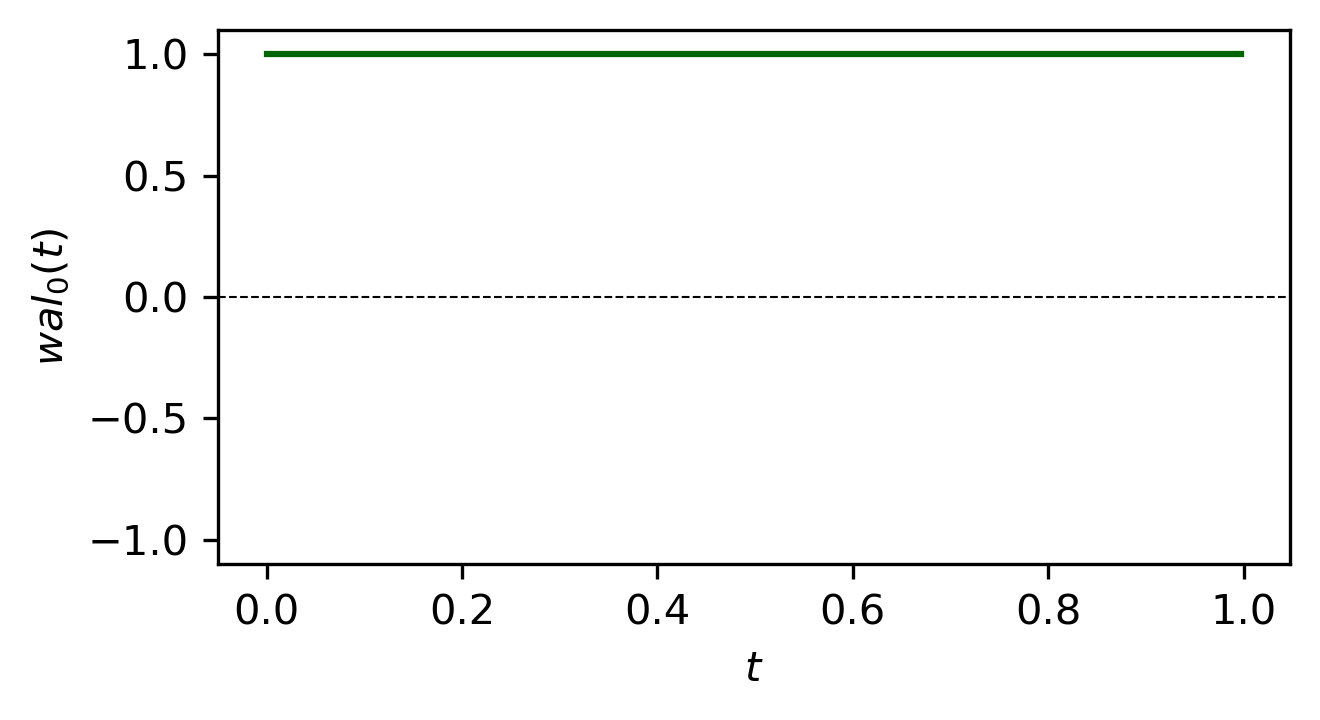

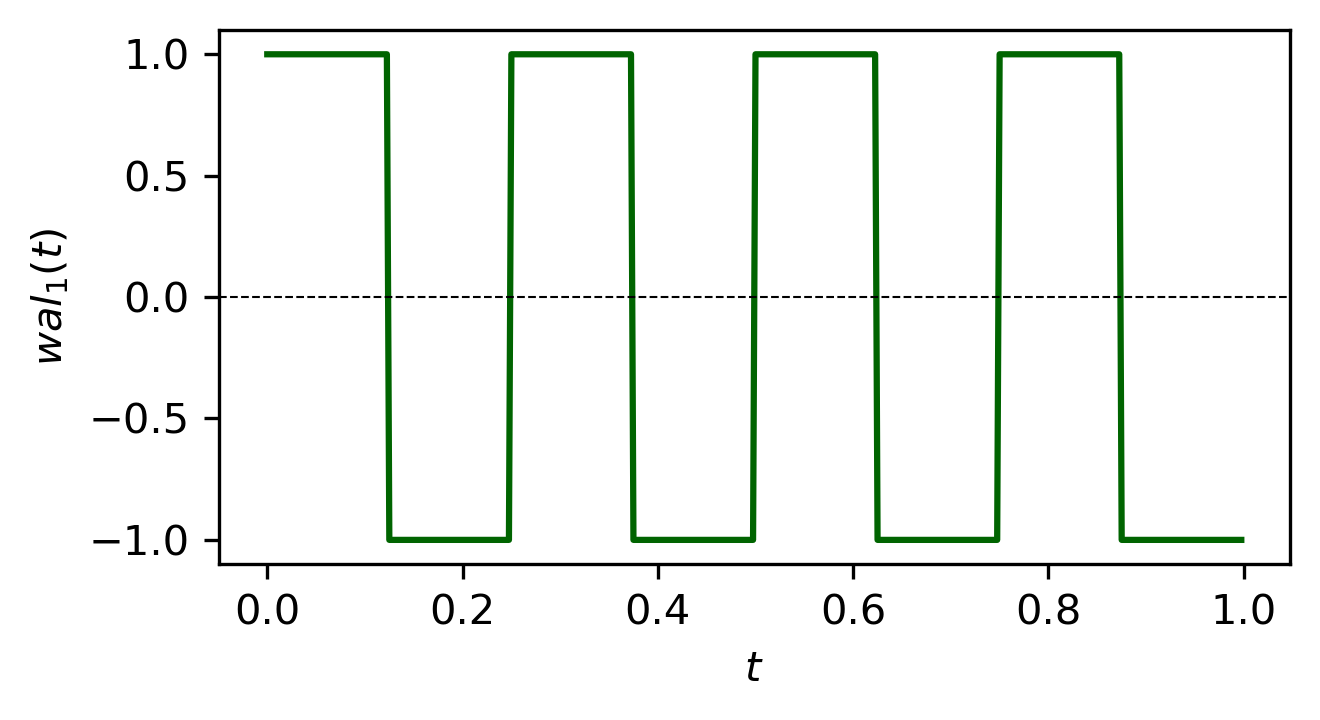

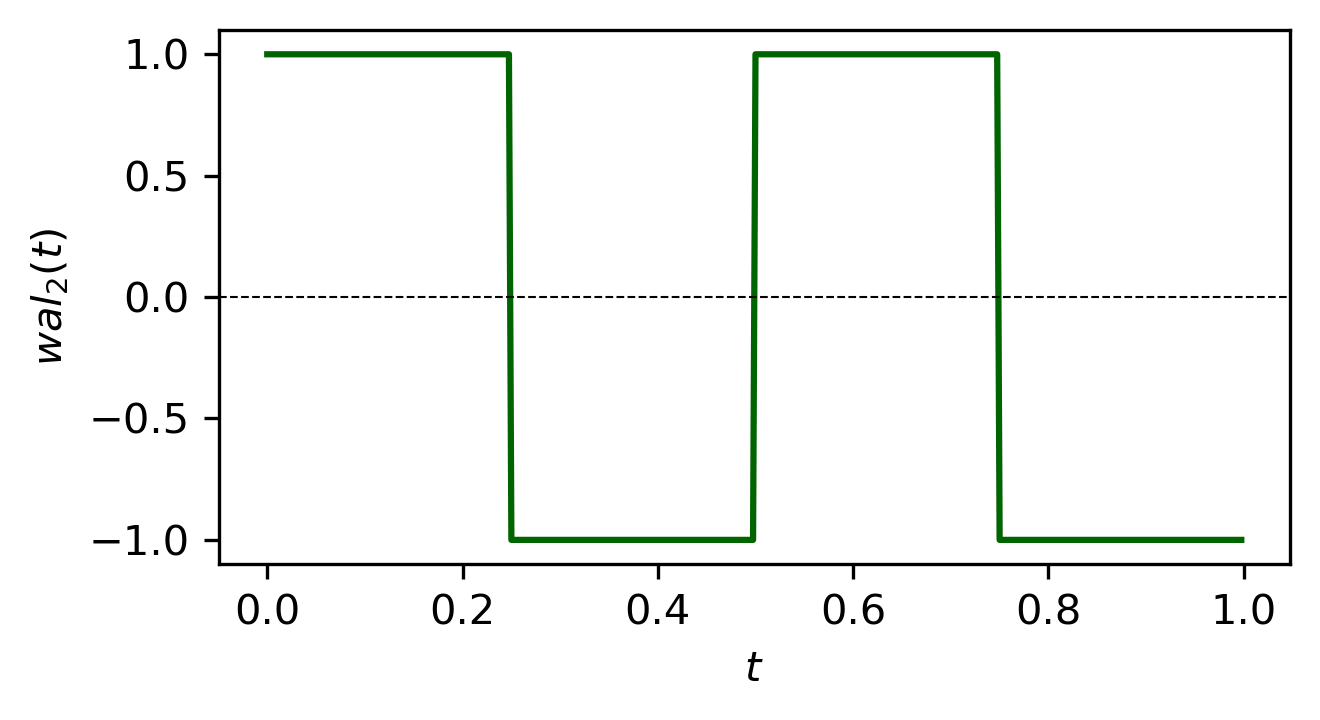

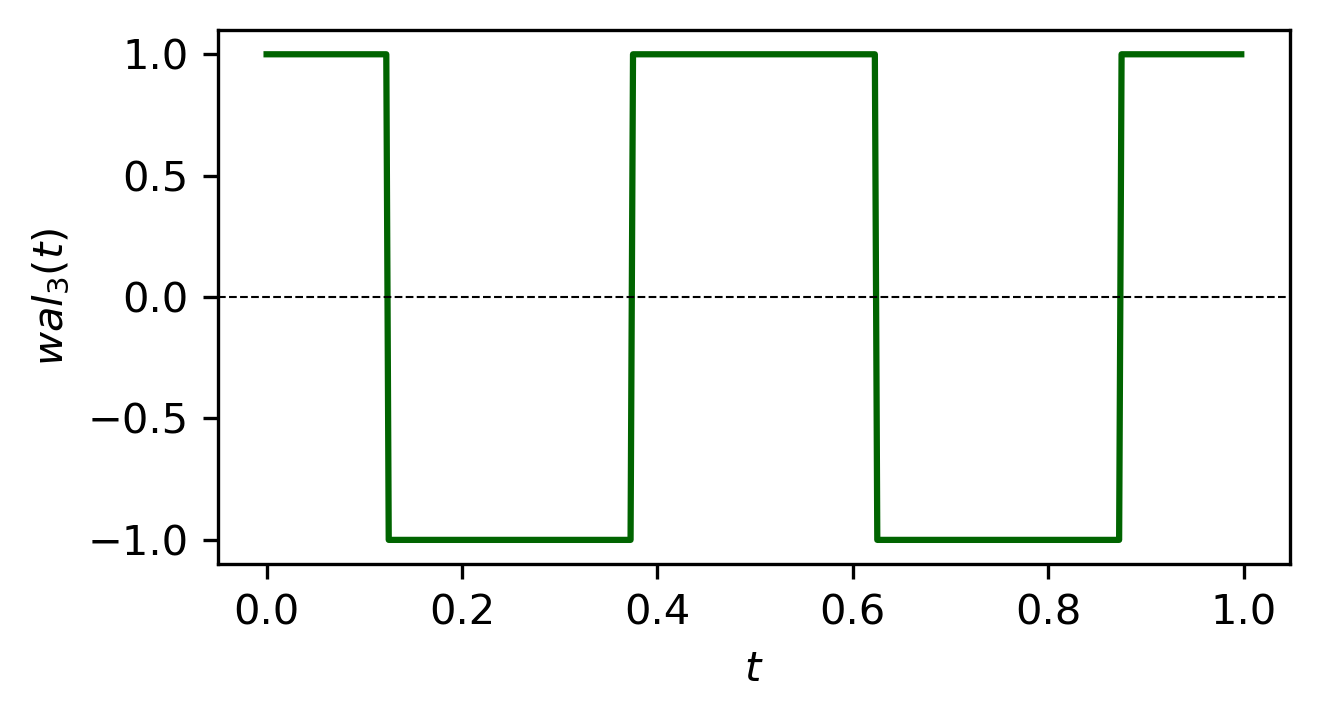

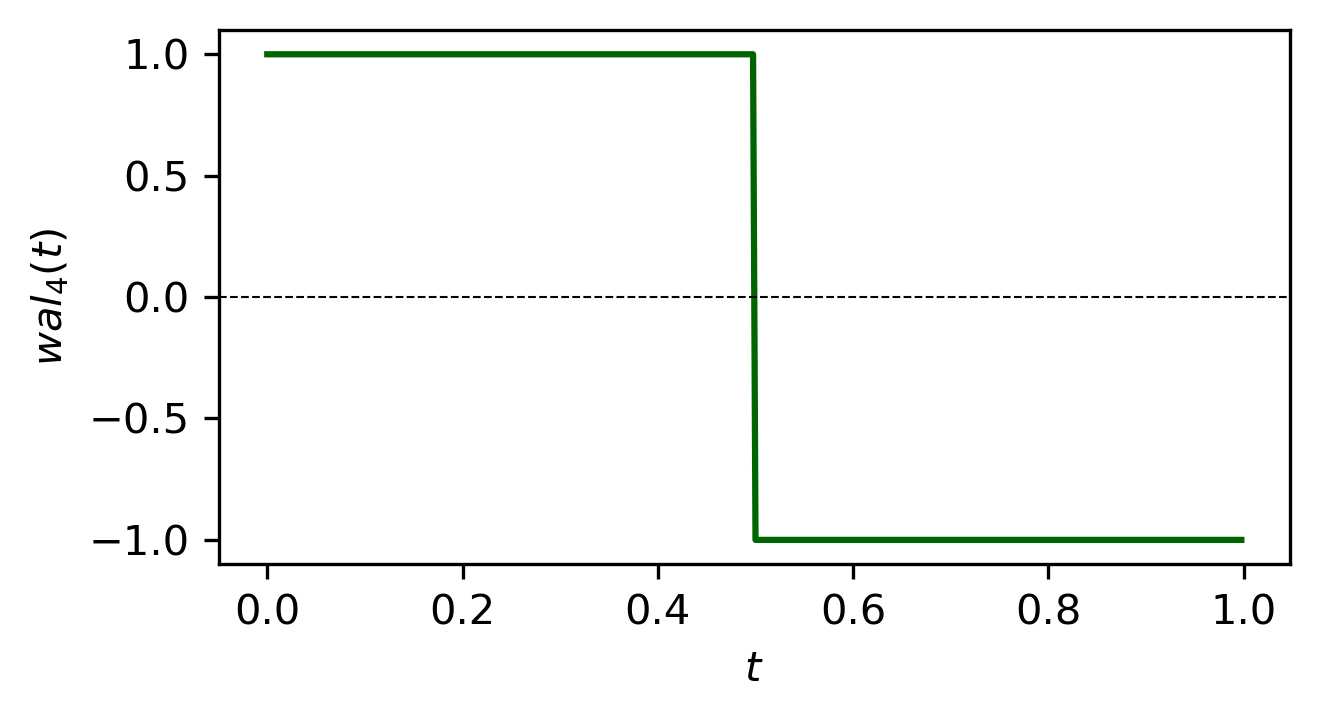

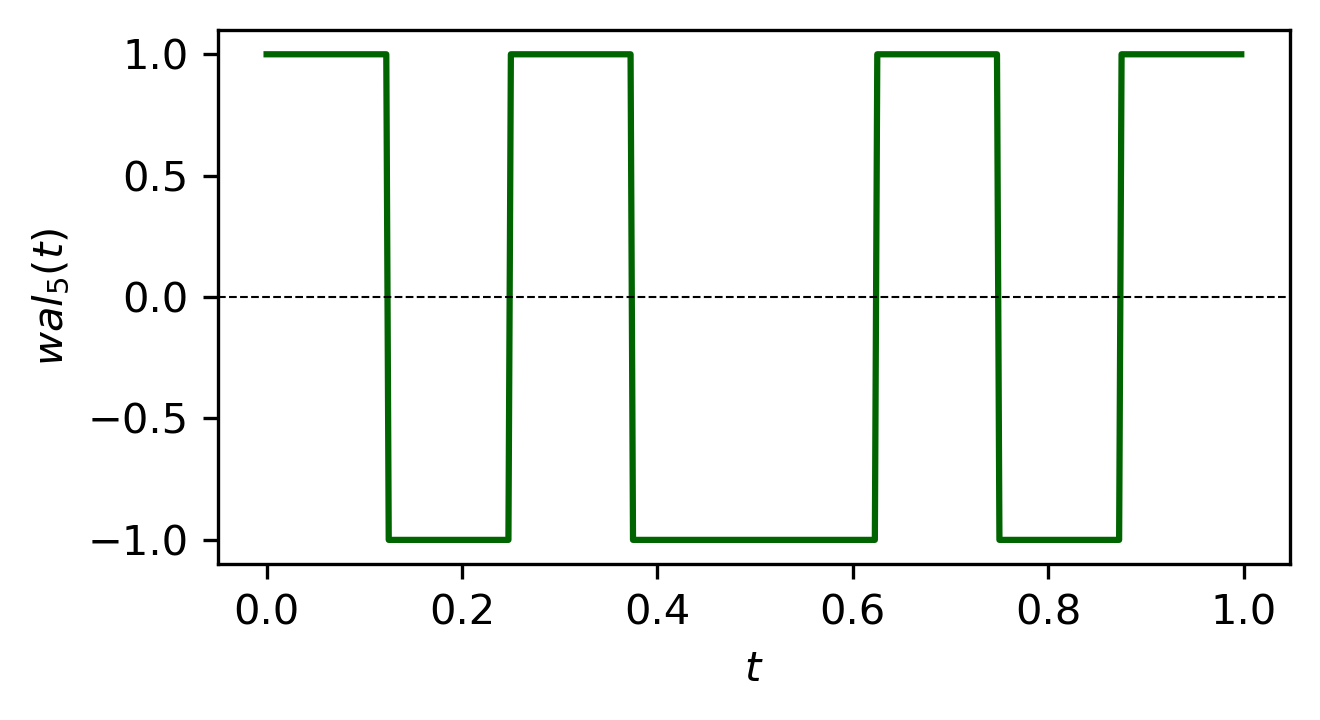

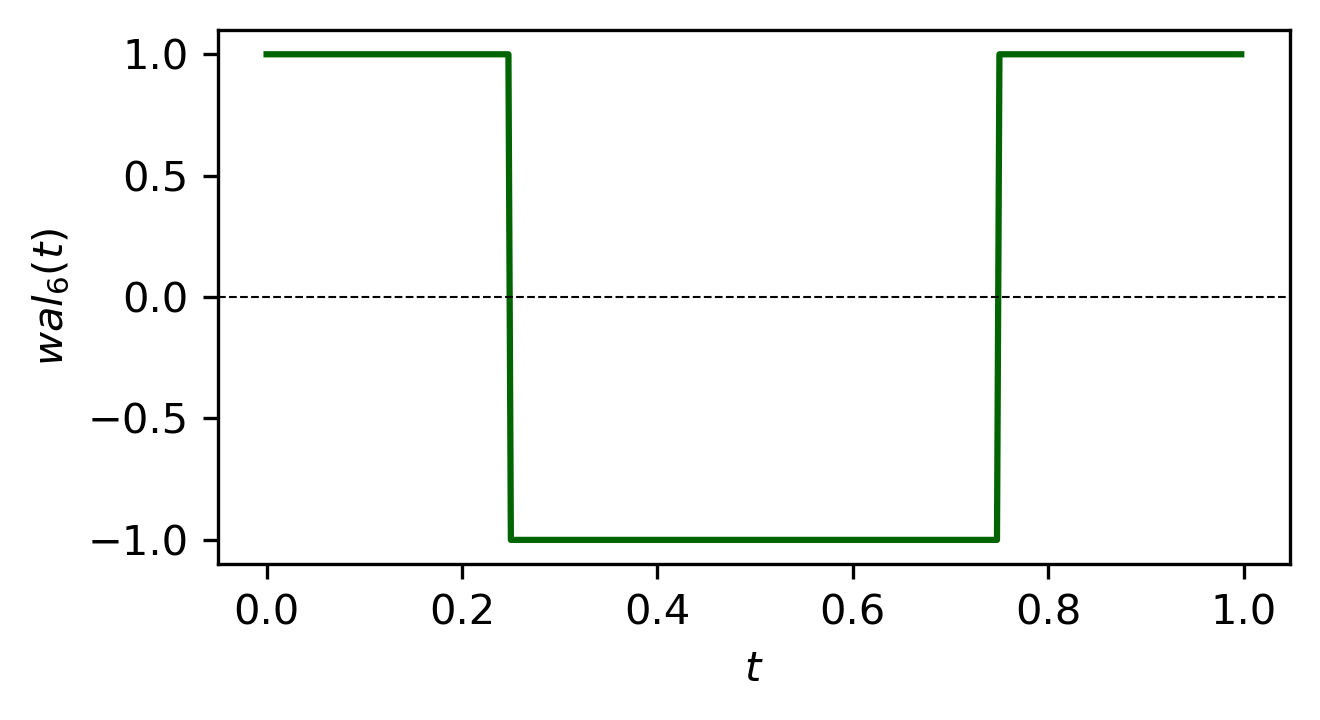

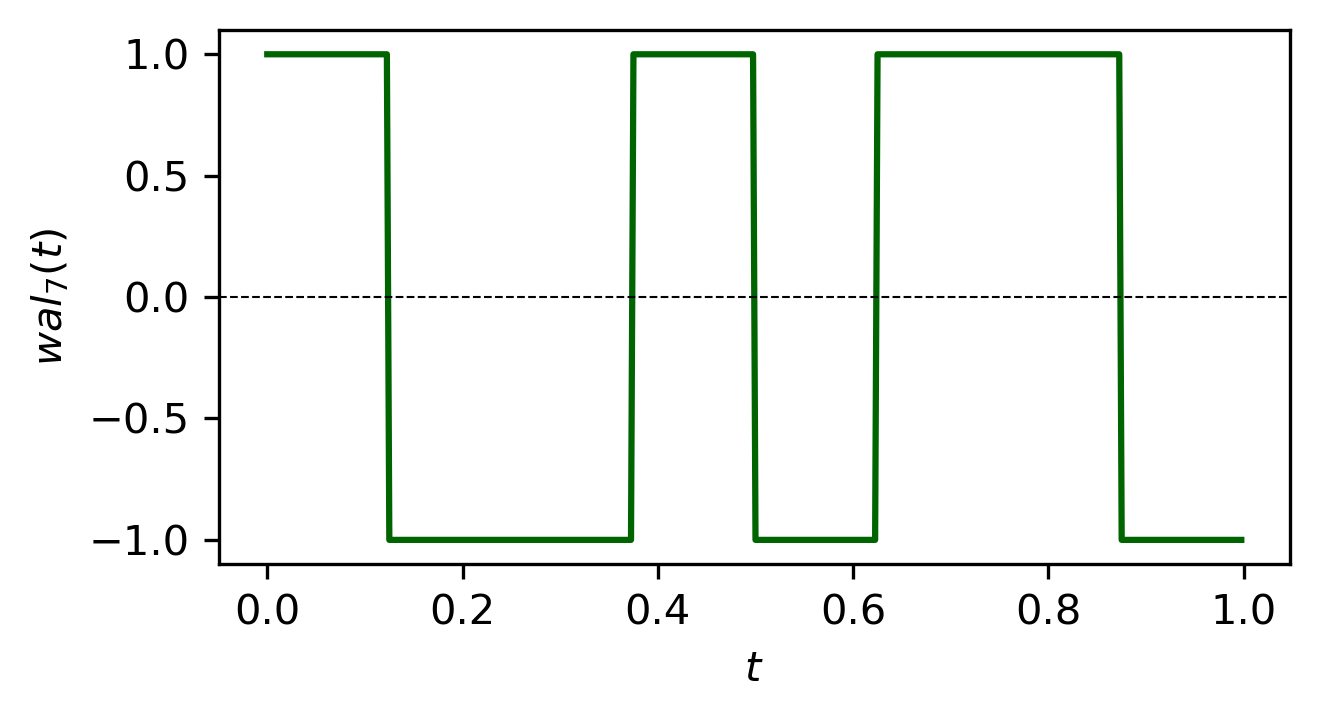

In [7]:
wal = np.zeros((N, L))

for k in range(N):           # za svaku Walsh funkciju
    for j in range(N):       # za svaki segment
        wal[k, j*d:(j+1)*d] = W[k, j]

for m in range(N):
    sis.dijagram(t=t, x=wal[m, :], 
                 y_labela=f'$wal_{m}(t)$', ylim=(-1.1, 1.1))

In [8]:
# =========================================================
# Kod 4.4 - Racunanje koeficijenata aproksimacije
# =========================================================

In [9]:
f = np.cos(2 * np.pi * t)   # funkcija koju aproksimiramo

# koeficijenti p(k) = integral f(t) na k-tom segmentu
p = np.zeros(N)
for k in range(N):
    p[k] = np.sum(f[k*d:(k+1)*d]) * Tmin

print(f"Koeficijenti p: {np.round(p, 4)}")

# koeficijenti Ck = W * p
C = W @ p

print("Koeficijenti C:")
for k in range(len(C)):
    print(f"  C[{k}] = {np.round(C[k], 4)}")

Koeficijenti p: [ 0.1129  0.0475 -0.0457 -0.1122 -0.1129 -0.0475  0.0457  0.1122]
Koeficijenti C:
  C[0] = 0.0
  C[1] = 0.0
  C[2] = 0.0
  C[3] = 0.0
  C[4] = 0.005
  C[5] = 0.2637
  C[6] = 0.6366
  C[7] = -0.0021


In [10]:
# =========================================================
# Kod 4.5 - Rekonstrukcija aproksimirane funkcije i grafik
# =========================================================

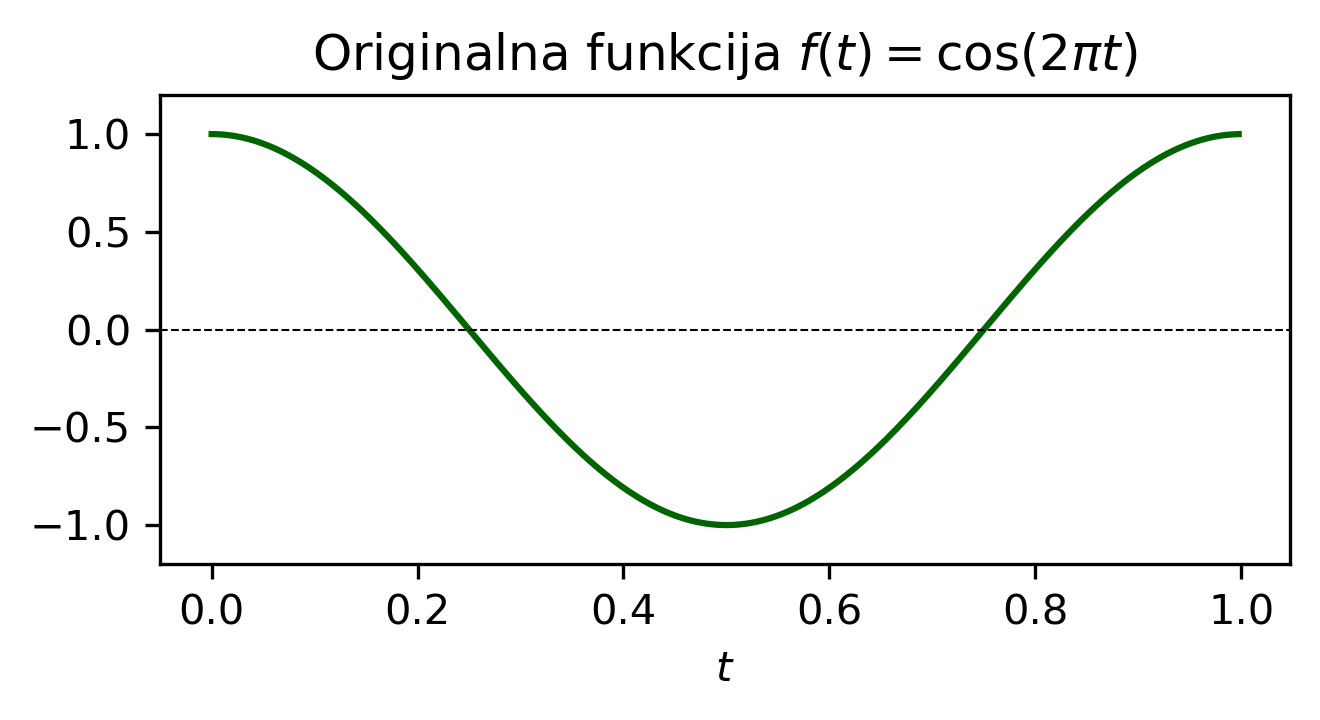

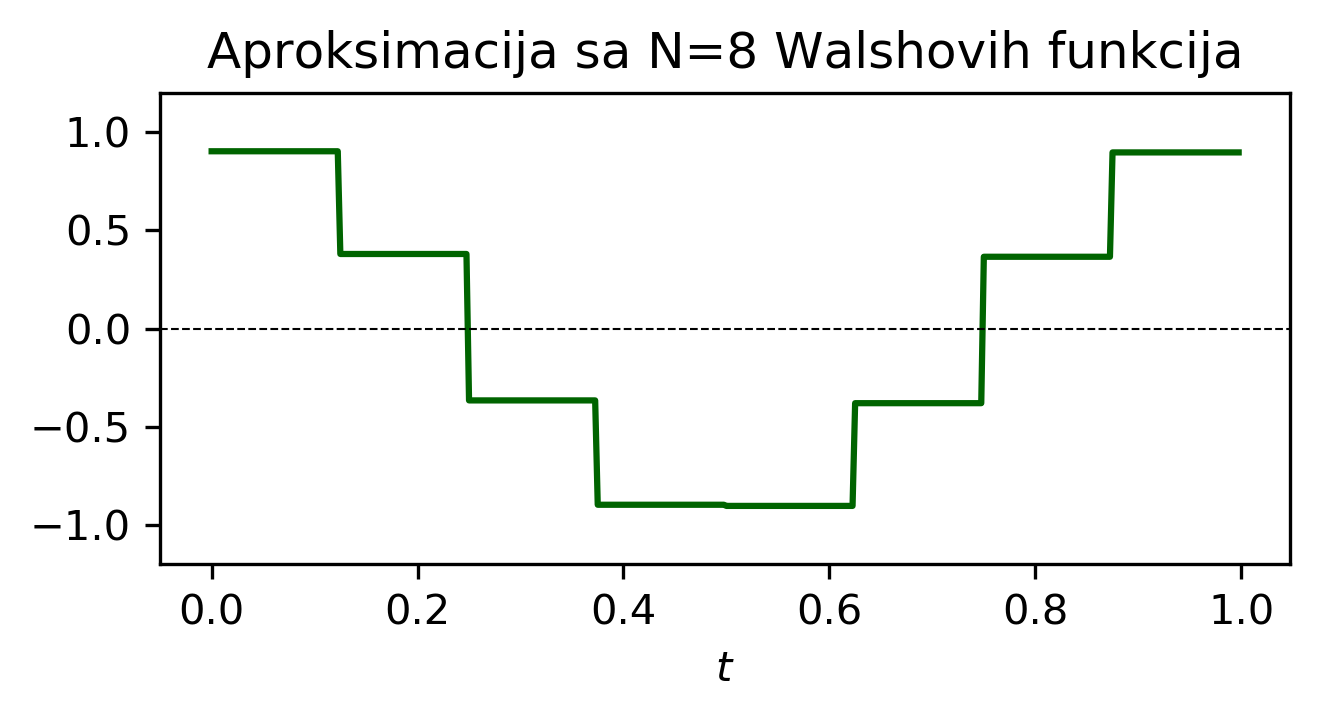

In [11]:
aprox = np.zeros(L)
for r in range(N):
    aprox += C[r] * wal[r, :]

sis.dijagram(t, f, 
             ylim=(-1.2, 1.2), 
             naslov=r'Originalna funkcija $f(t) = \cos(2\pi t)$')

sis.dijagram(t, aprox, 
             ylim=(-1.2, 1.2),
             naslov=f'Aproksimacija sa N={N} Walshovih funkcija')